# IndieScope: EDA and design evidence
This executed notebook uses Pandas and Matplotlib on the compact paid Indie cohort. The accompanying audit was computed by streaming all 125,855 original rows, repairing the header before mapping fields. The original 401 MB file is not required to rerun this notebook. We distinguish dataset facts from proposed business decisions. Cutoff: 2026-10-12; source collection date unknown.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.options.display.float_format = '{:.3f}'.format
root = Path.cwd()
audit = json.loads((root / 'data/audit.json').read_text())
df = pd.read_csv(root / 'data/indie_games.csv.gz')
df['Release date'] = pd.to_datetime(df['Release date'])
print('Raw records:', audit['counts']['raw_rows'])
print('Header columns: 39 original -> 40 corrected; Discount / DLC count split')
print('Export shape:', df.shape, '; bytes:', audit['export_bytes'])
print('Cutoff:', audit['analysis_cutoff'], '; collection date:', audit['snapshot_collection_date'])
display(df.dtypes.to_frame('dtype'))
display(df.head(3))

Matplotlib is building the font cache; this may take a moment.


Raw records: 125855
Header columns: 39 original -> 40 corrected; Discount / DLC count split
Export shape: (51404, 14) ; bytes: 14496896
Cutoff: 2026-10-12 ; collection date: not supplied


,dtype
AppID,int64
Name,str
Release date,datetime64[us]
Price,float64
Discount,float64
Positive,int64
Negative,int64
Genres,str
Tags,str
Developers,str


,AppID,Name,Release date,Price,Discount,Positive,Negative,Genres,Tags,Developers,Publishers,Review count,Positive rate,Steam URL
0,3292190,버튜버 파라노이아 - Vtuber Paranoia,2024-10-31,8.990,0.000,0,0,"Casual,Indie,Simulation",NaN,유진게임즈,유진게임즈,0,NaN,https://store.steampowered.com/app/3292190/
1,1157670,Hepta Beats,2021-05-07,0.990,0.000,28,4,"Casual,Indie","Precision Platformer,Rhythm,Music,Difficult,Ab...",Matheus Bigatão,Matheus Bigatão,32,87.500,https://store.steampowered.com/app/1157670/
2,1540330,MUMBA IV: Egypt Jewels,2021-12-13,0.590,0.000,19,6,"Action,Casual,Indie,Strategy","Casual,Action,Strategy,Puzzle,Match 3,Singlepl...",Airem,Airem,25,76.000,https://store.steampowered.com/app/1540330/


## Missing data and zero reviews
Blank tags are not imputed. Missing genre labels cannot establish Indie membership. Zero reviews produce no approval score, rather than 0% approval.

In [2]:
raw_missing = pd.Series(audit['missing_raw']).sort_values(ascending=False)
display(raw_missing.to_frame('missing raw rows'))
display(df.isna().sum().to_frame('missing in compact cohort'))
print('Zero-review raw apps:', audit['counts']['zero_reviews'])
print('Duplicate compact AppIDs:', df['AppID'].duplicated().sum())
assert df['AppID'].is_unique
assert df['Price'].between(0,40,inclusive='right').all()
assert (df['Release date'] <= pd.Timestamp(audit['analysis_cutoff'])).all()
assert df.loc[df['Review count']==0,'Positive rate'].isna().all()
assert ((df['Positive']+df['Negative'])==df['Review count']).all()

,missing raw rows
Movies,125855
Score rank,125815
Metacritic url,121597
Reviews,113674
Notes,102544
Website,75335
Support url,70493
Tags,42502
Support email,22610
Categories,8966


,missing in compact cohort
AppID,0
Name,0
Release date,0
Price,0
Discount,0
Positive,0
Negative,0
Genres,0
Tags,16127
Developers,39


Zero-review raw apps: 42899
Duplicate compact AppIDs: 0


## Distributions
The full catalogue contains many free apps and apps with few reviews. The compact cohort selects a specific paid-game segment; it is not the entire market.

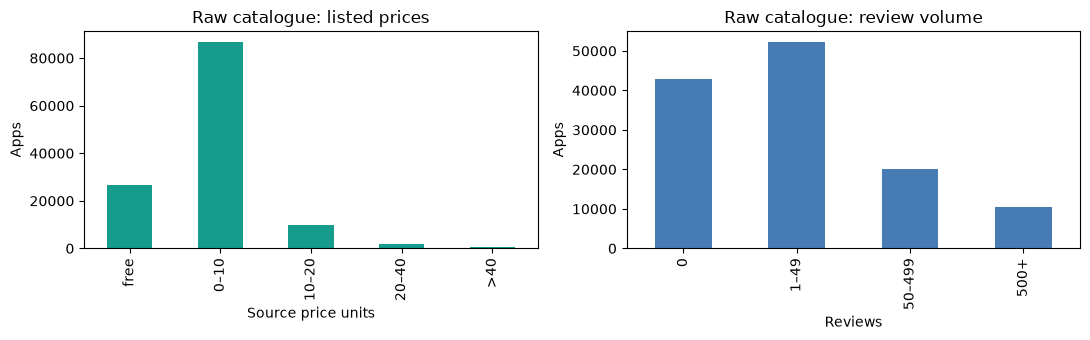

,Price,Review count,Positive rate,Discount
count,51404.000,51404.000,35073.000,51404.000
mean,4.826,415.421,79.540,20.680
std,4.661,7254.883,24.099,28.601
min,0.490,0.000,0.000,0.000
25%,1.490,0.000,69.468,0.000
50%,3.390,5.000,87.292,0.000
75%,6.390,28.000,100.000,50.000
95%,14.990,557.000,100.000,80.000
99%,19.990,5659.130,100.000,90.000
max,39.990,768779.000,100.000,100.000


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
pd.Series(audit['raw_price_bins']).plot.bar(ax=axes[0], color='#159c8c')
axes[0].set(title='Raw catalogue: listed prices', ylabel='Apps', xlabel='Source price units')
pd.Series(audit['raw_review_bins']).reindex(['0','1–49','50–499','500+']).plot.bar(ax=axes[1], color='#477bb4')
axes[1].set(title='Raw catalogue: review volume', ylabel='Apps', xlabel='Reviews')
plt.tight_layout(); plt.show()
display(df[['Price','Review count','Positive rate','Discount']].describe(percentiles=[.25,.5,.75,.95,.99]))

## Review threshold sensitivity and relationships
The 50-review default is a screening choice. We compare alternatives rather than treating it as proof of statistical reliability. Approval is the median per game, not review-weighted approval. Correlation is descriptive and does not identify the effect of changing a price.

,minimum_reviews,games,median_price,median_approval_pct
0,0,51404,3.390,87.292
1,10,20991,3.740,85.714
2,50,9520,4.990,86.000
3,100,6663,4.990,86.354
4,500,2754,6.490,88.108
5,1000,1778,6.990,89.419


,Price,Review count,Positive rate
Price,1.000,0.238,0.033
Review count,0.238,1.000,0.101
Positive rate,0.033,0.101,1.000


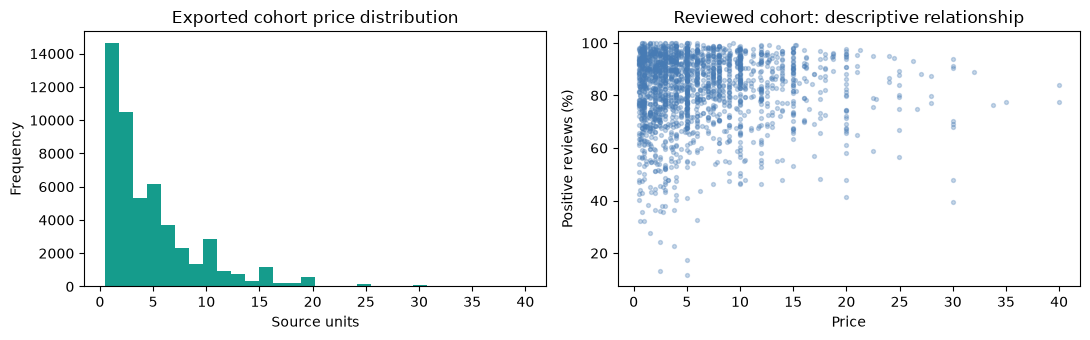

In [4]:
sensitivity=[]
for threshold in [0,10,50,100,500,1000]:
    peers=df.loc[df['Review count']>=threshold]
    sensitivity.append({'minimum_reviews':threshold,'games':len(peers),'median_price':peers['Price'].median(),'median_approval_pct':peers['Positive rate'].median()})
display(pd.DataFrame(sensitivity))
reviewed=df.loc[df['Review count']>=50]
display(reviewed[['Price','Review count','Positive rate']].corr(method='spearman'))
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
df['Price'].plot.hist(bins=30,ax=axes[0],color='#159c8c');axes[0].set(title='Exported cohort price distribution',xlabel='Source units')
reviewed.sample(min(2000,len(reviewed)),random_state=42).plot.scatter(x='Price',y='Positive rate',ax=axes[1],s=8,alpha=.3,color='#477bb4')
axes[1].set(title='Reviewed cohort: descriptive relationship',ylabel='Positive reviews (%)')
plt.tight_layout();plt.show()

## Default Strategy peer set and example research targets
The opening view is Strategy with at least 50 reviews. The following table is a starting point for live store-page inspection, not a list of commercially optimal games.

In [5]:
strategy=df.loc[df['Genres'].fillna('').map(lambda s:'Strategy' in [g.strip() for g in s.split(',')]) & df['Review count'].ge(50)]
print(f'Games: {len(strategy):,}; median price: {strategy.Price.median():.3f}; median approval: {strategy["Positive rate"].median():.3f}%')
display(strategy.sort_values('Review count',ascending=False)[['Name','Price','Discount','Positive rate','Review count','Release date','Steam URL']].head(10))

Games: 2,200; median price: 5.750; median approval: 83.502%


,Name,Price,Discount,Positive rate,Review count,Release date,Steam URL
8575,7 Days to Die,24.740,45.000,88.608,370046,2024-07-25,https://store.steampowered.com/app/251570/
30370,Mount & Blade II: Bannerlord,24.990,50.000,87.885,264391,2022-10-25,https://store.steampowered.com/app/261550/
2124,Satisfactory,27.990,30.000,97.162,232064,2024-09-10,https://store.steampowered.com/app/526870/
38842,Factorio,35.000,0.000,97.008,215209,2020-08-14,https://store.steampowered.com/app/427520/
36108,Squad,19.990,60.000,83.157,210551,2020-09-23,https://store.steampowered.com/app/393380/
40016,Schedule I,13.990,30.000,98.413,204041,2025-03-24,https://store.steampowered.com/app/3164500/
6772,Balatro,12.740,0.000,98.019,153566,2024-02-20,https://store.steampowered.com/app/2379780/
27550,Hell Let Loose,12.490,75.000,82.401,137677,2021-07-27,https://store.steampowered.com/app/686810/
14268,Totally Accurate Battle Simulator,6.790,66.000,97.816,135943,2021-04-01,https://store.steampowered.com/app/508440/
44335,Inscryption,7.990,60.000,96.893,131890,2021-10-19,https://store.steampowered.com/app/1092790/


## Decisions justified by the EDA
- Many zero-review apps motivate optional review screening and undefined approval for no-review titles.
- Missing tags motivate optional tag filters, not invented labels.
- Skewed feedback volume motivates displaying review counts alongside approval.
- We use price and per-game approval medians for peer context, not revenue estimates.
- Year filtering controls the release cohort, but does not establish equal exposure periods.
- The raw header repair is necessary before all of these conclusions.

Production weekly snapshots and a proposed approval-drop investigation rule are future design choices. Neither historical change nor live alerting is measured from this snapshot.